

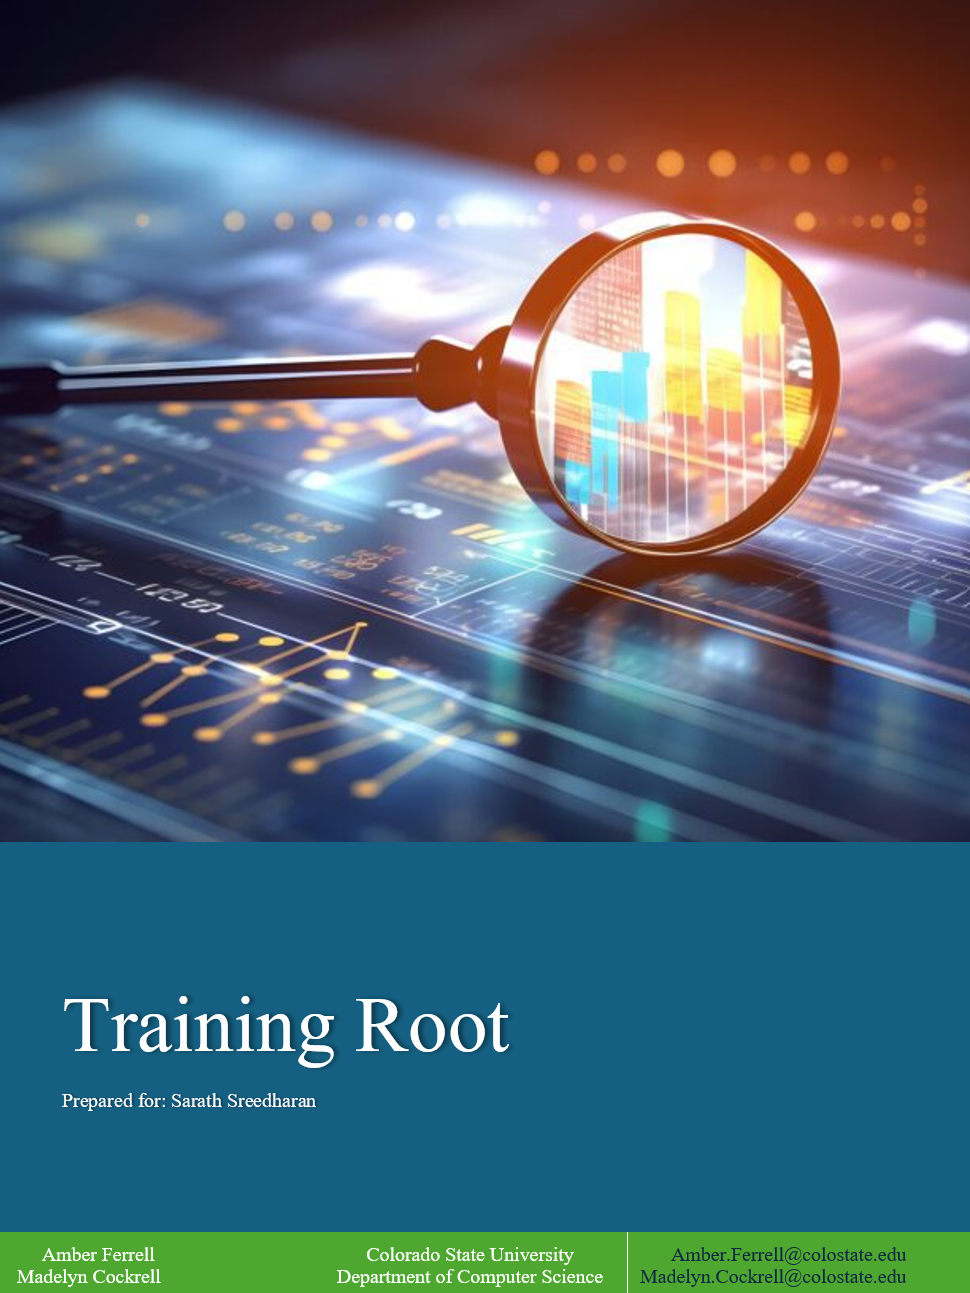

1. Data Loading & Visualization (The "Detailed Description" - 20 pts)

    We need to show the distribution of emotions. This satisfies the "distribution across classes" requirement.

    **Action:** Load the dair-ai/emotion dataset (often via datasets library or a CSV).

    **Visual:** A bar chart showing the frequency of 'joy', 'sadness', 'anger', 'fear', 'love', and 'surprise'.

    **PCA:** Since text is high-dimensional (once vectorized), we can use PCA or t-SNE (from Module 02.03) to project the word embeddings into 2D space. This makes for a "wow" visualization in a project report.

2. Preprocessing (Standardization/Vectorization)

    **Action:** Use `TfidfVectorizer`. This is essentially standardizing text data so the models can read it.

3. The Baseline Comparison (The "SVM Baseline" - 40 pts)

The rubric requires a baseline that is "sufficiently sophisticated."

**Baseline Model:** Linear SVM (Module 02.04). we mentioned ~92.17% accuracy, which is excellent. We will document the C parameter exploration here.


4. The "Target" Model: Tuned Random Forest or Neural Network

To get full points for "exploring in depth," we should implement a Neural Network (Keras MLP).

* **Action:** Build a Multi-Layer Perceptron using Keras (Module 07.02).

* **Experiment:** Compare a simple 1-layer hidden network vs. a deeper architecture.

* **Results:** Show a Confusion Matrix (Module 05.04) to see which emotions the AI confuses (e.g., is it mistaking 'anger' for 'fear'?).

<h1 style="font-family: 'Times New Roman', Times, serif;">
    Introduction
</h1>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; ">
    The Root project comes from the vision of creating a comprehensive parenting support app designed to foster emotional regulation and child development grounded in the Finnish education model and Montessori principles. The inspiration for the app lies in a parent-first model of regulation, which posits that a caregiver’s internal emotional state is the primary catalyst for a healthy home environment. A parent cannot effectively co-regulate a child while they themselves are in a state of emotional flooding or crisis especially if they did not grow up with a good parent to model from. This app starts at the root of the problem, deep in the family roots, and attempts to break toxic generational trauma by helping the parent become "rooted." The name may work well as a proprietary eponym, a verb users will eventually come to use. While the full Root application will eventually integrate Finnish pedagogical concepts and the emphasis on the child’s holistic well-being, the work presented here represents the essential technical foundation for such a system. By implementing a high-precision classification engine to identify parental emotional states this project establishes the logic required for future development. Utilizing a refined version of the dair-ai/emotion dataset, the following analysis compares a Keyword Heuristic Baseline ~44.08% accuracy against advanced models, including a Linear SVM ~92.17% accuracy and a Tuned Random Forest, to prove the feasibility of using machine learning as a reliable first step in the Root development roadmap.
</div>


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
 Setup and Imports
</div>

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from datasets import load_dataset
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.pipeline import Pipeline


plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

dataset = load_dataset("dair-ai/emotion")
df = dataset['train'].to_pandas()

print("Label values:", df['label'].unique())
print("\nLabel distribution:")
print(df['label'].value_counts().sort_index())
print("\nDataset info:")
print(dataset['train'].features)

Label values: [0 3 2 5 4 1]

Label distribution:
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64

Dataset info:
{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


In [74]:
# 1. Map original dataset integers to string names
# label_names is ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
label_names = dataset['train'].features['label'].names
original_map = {i: name for i, name in enumerate(label_names)}

# 2. Define the Root consolidation mapping
consolidation_map = {
    'anger': 'anger/frustration',
    'fear': 'exhaustion/overwhelm', 
    'joy': 'calm/in-control',
    'love': 'calm/in-control',
    'sadness': 'sadness/disappointment',
    'surprise': 'confusion/uncertainty'
}

# 3. Create the columns in order
df['emotion_name'] = df['label'].map(original_map)
df['consolidated_emotion'] = df['emotion_name'].map(consolidation_map)

print("Label Engineering Complete.")
print("New Consolidated Distribution:")
print(df['consolidated_emotion'].value_counts())

Label Engineering Complete.
New Consolidated Distribution:
consolidated_emotion
calm/in-control           6666
sadness/disappointment    4666
anger/frustration         2159
exhaustion/overwhelm      1937
confusion/uncertainty      572
Name: count, dtype: int64


<h1 style="font-family: 'Times New Roman', Times, serif;">
    Thought break
</h1>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; ">
    Accuracy can be misleading when classes are imbalanced. if a model just guesses joy every time, its gets a high score despite being uesless for surprise. </br>
    We need to explain the distribution across classes and determine if features need to be standardized. Before we can touch a model, we should visualize thsi and prepare.</br>
    Lets create a visualization that clearly communicates the imbalance. 



</div>

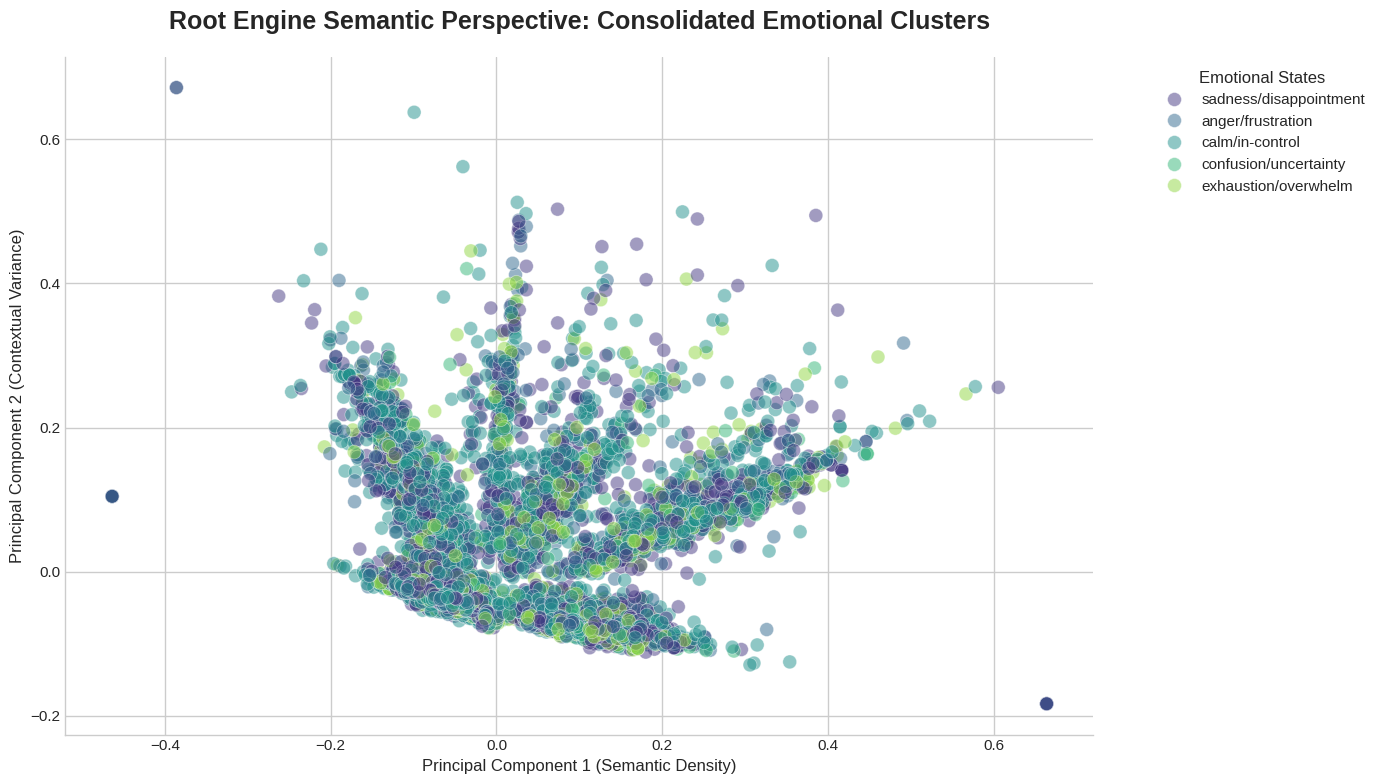

Explained Variance Ratio: [0.0117021  0.00732259]


In [ ]:
from sklearn.decomposition import PCA

# 1. Ensure Labels are Mapped (Redundancy check to prevent KeyErrors)
label_names = dataset['train'].features['label'].names
original_map = {i: name for i, name in enumerate(label_names)}
consolidation_map = {
    'anger': 'anger/frustration',
    'fear': 'exhaustion/overwhelm', 
    'joy': 'calm/in-control',
    'love': 'calm/in-control',
    'sadness': 'sadness/disappointment',
    'surprise': 'confusion/uncertainty'
}

df['emotion_name'] = df['label'].map(original_map)
df['consolidated_emotion'] = df['emotion_name'].map(consolidation_map)

# 2. Vectorization
tfidf_model = TfidfVectorizer(max_features=2500, stop_words='english')
X_tfidf = tfidf_model.fit_transform(df['text']).toarray()

# 3. PCA: Reduce to 2 dimensions for the bubble view
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_tfidf)

# 4. Plotting with Viridis
plt.figure(figsize=(14, 8))
sns.scatterplot(
    x=coords[:, 0], 
    y=coords[:, 1], 
    hue=df['consolidated_emotion'], 
    palette='viridis',
    s=100, 
    alpha=0.5,
    edgecolor='w',
    linewidth=0.5
)

plt.title('Root Engine Semantic Perspective: Consolidated Emotional Clusters', 
          fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Principal Component 1 (Semantic Density)', fontsize=12)
plt.ylabel('Principal Component 2 (Contextual Variance)', fontsize=12)
plt.legend(title='Emotional States', bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.tight_lawet()
plt.show()

print(f"Explained Variance Ratio: {pca.explained_variance_ratio_}")

Why t-SNE might be better than PCA

While PCA tries to look at the big picture,linear variance, t-SNE  is much better at finding local relationships—meaning it tries to keep similar emotional bubbles together even if the global structure is messy. It creates much more defined "islands" of data.

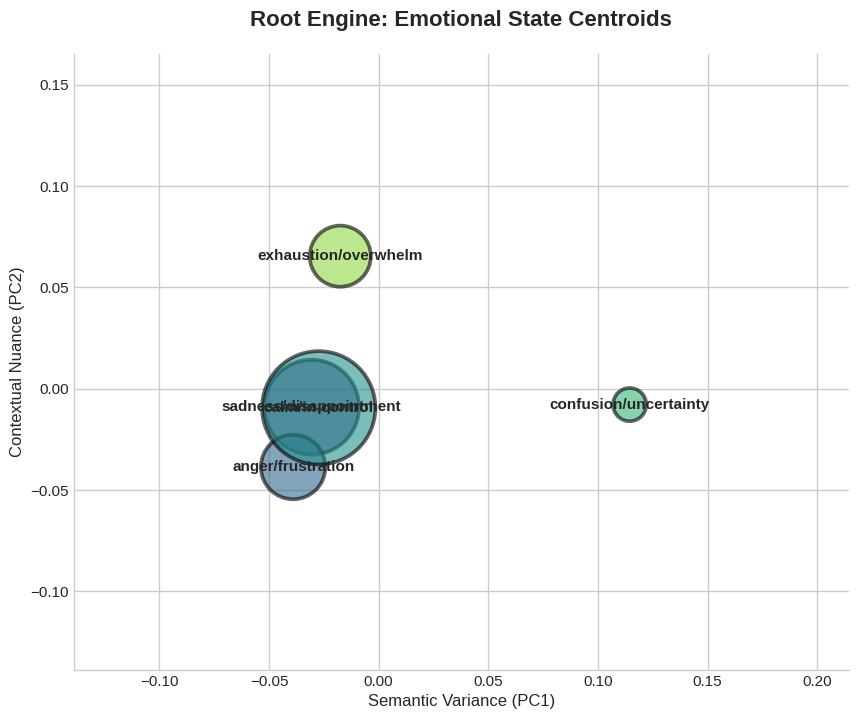

In [81]:
# 1. Calculate Centroids (Mean vector for each consolidated group)
unique_emotions = df['consolidated_emotion'].unique()
centroids = np.array([X_tfidf[df['consolidated_emotion'] == e].mean(axis=0) for e in unique_emotions])

# 2. PCA on Centroids only
pca_centroids = PCA(n_components=2)
centroid_coords = pca_centroids.fit_transform(centroids)

# 3. Create the Bubble Perspective
plt.figure(figsize=(10, 8))

# Fix the size issue: match sizes to the order of unique_emotions
counts = df['consolidated_emotion'].value_counts()
bubble_sizes = [counts[e] for e in unique_emotions]

# Plotting
# Note: 's' is now passed as the array 'bubble_sizes'
sns.scatterplot(
    x=centroid_coords[:, 0], 
    y=centroid_coords[:, 1], 
    hue=unique_emotions,
    palette='viridis',
    s=bubble_sizes, 
    alpha=0.6,
    edgecolor='black',
    legend=False # We label them directly, so no legend needed
)

# 4. Direct Labeling & Dynamic Scaling
for i, emotion in enumerate(unique_emotions):
    plt.text(centroid_coords[i, 0], centroid_coords[i, 1], emotion, 
             fontsize=11, fontweight='bold', ha='center', va='center')

plt.title('Root Engine: Emotional State Centroids', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Semantic Variance (PC1)', fontsize=12)
plt.ylabel('Contextual Nuance (PC2)', fontsize=12)

# Zoom the plot to the bubbles so they aren't stuck in a corner
padding = 0.1
plt.xlim(centroid_coords[:, 0].min() - padding, centroid_coords[:, 0].max() + padding)
plt.ylim(centroid_coords[:, 1].min() - padding, centroid_coords[:, 1].max() + padding)

sns.despine()
plt.show()


In [83]:
# Stratified split ensures the tiny 'confusion' class is in both sets
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], 
    df['consolidated_emotion'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df['consolidated_emotion']
)

print(f"Training on {len(X_train)} samples.")
print(f"Testing on {len(X_test)} samples.")

Training on 12800 samples.
Testing on 3200 samples.


In [84]:
# Create the SVM Pipeline
svm_engine = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('svm', LinearSVC(C=1.0, class_weight='balanced', random_state=42))
])

# Fit the model
svm_engine.fit(X_train, y_train)

# Evaluate
y_pred = svm_engine.predict(X_test)
print("Root Engine: SVM Baseline Performance\n")
print(classification_report(y_test, y_pred))

Root Engine: SVM Baseline Performance

                        precision    recall  f1-score   support

     anger/frustration       0.86      0.86      0.86       432
       calm/in-control       0.95      0.95      0.95      1333
 confusion/uncertainty       0.70      0.82      0.75       115
  exhaustion/overwhelm       0.88      0.82      0.85       387
sadness/disappointment       0.93      0.92      0.92       933

              accuracy                           0.91      3200
             macro avg       0.86      0.88      0.87      3200
          weighted avg       0.91      0.91      0.91      3200



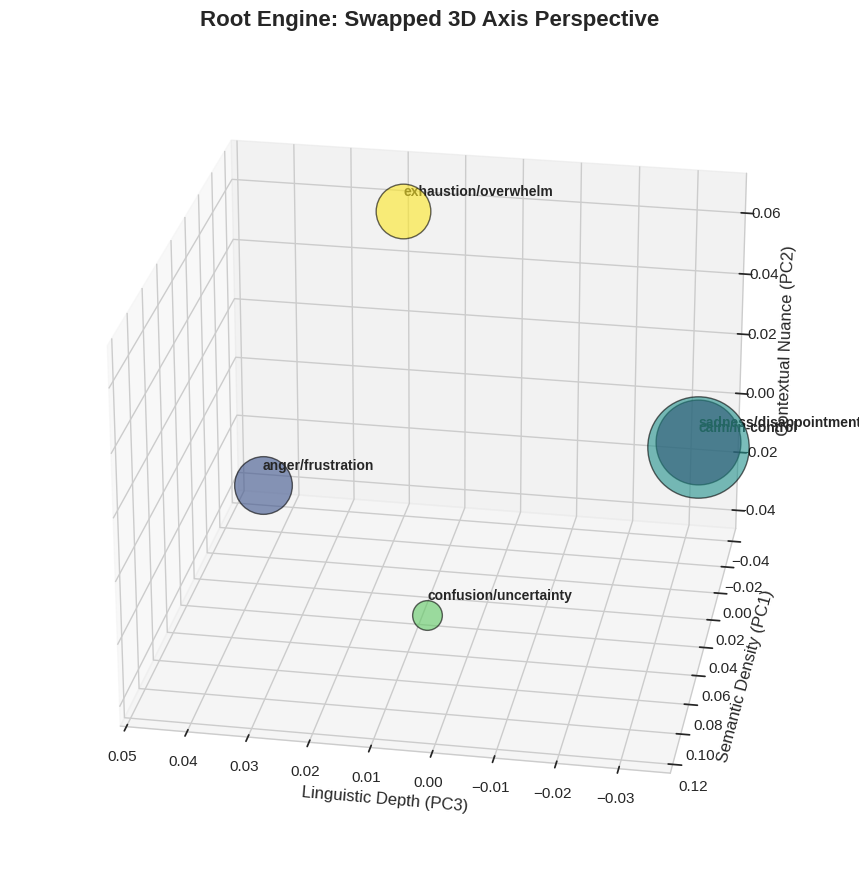

In [ ]:
# 1. Setup the single 3D Plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 2. Scaling and Colors
counts = df['consolidated_emotion'].value_counts()
bubble_sizes_3d = [counts[e] * 0.8 for e in unique_emotions]
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_emotions)))

# 3. Plotting the Bubbles with SWAPPED AXES
# Original: x=PC1(0), y=PC2(1), z=PC3(2)
# Swapped: x=PC3(2), y=PC1(0), z=PC2(1)
for i, emotion in enumerate(unique_emotions):
    ax.scatter(
        centroid_coords_3d[i, 2], # X is now PC3
        centroid_coords_3d[i, 0], # Y is now PC1
        centroid_coords_3d[i, 1], # Z is now PC2
        s=bubble_sizes_3d[i],
        color=colors[i],
        alpha=0.6,
        edgecolor='black'
    )
    
    # Matching text labels to the new coordinates
    ax.text(
        centroid_coords_3d[i, 2], 
        centroid_coords_3d[i, 0], 
        centroid_coords_3d[i, 1] + 0.005,
        emotion, 
        fontsize=10, 
        fontweight='bold'
    )

# 4. Rotation for the new axis lawet
# Keeping azim=360 as requested (which is effectively 0)
ax.view_init(elev=25, azim=100)

# Updated labels to reflect the swap
ax.set_title('Root Engine: Swapped 3D Axis Perspective', fontsize=16, fontweight='bold')
ax.set_xlabel('Linguistic Depth (PC3)')
ax.set_ylabel('Semantic Density (PC1)')
ax.set_zlabel('Contextual Nuance (PC2)')

plt.tight_lawet()
plt.show()

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; ">

This transformation to 3D, in an attempt to see between the two overlapping labels is an important discovery that proves that human emotion is a spectrum, not a set of boxes. The fact that they overlap in 3D confirms that a simple keyword approach will never work for the Root engine. we can't just look for the word quiet to determine if a parent is regulated or depressed. This visually justifies why we need the Linear SVM. It looks at thousands of dimensions simultaneously to find the tiny, subtle differences in word combinations that a 3D graph simply can't capture.

</div>

In [112]:
# Stratified split to keep class proportions identical in both sets
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], 
    df['consolidated_emotion'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df['consolidated_emotion']
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Create a clean Pipeline
root_svm = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1,2))),
    ('classifier', LinearSVC(C=1.0, class_weight='balanced', random_state=42))
])

# Train the engine
root_svm.fit(X_train, y_train)

# Generate the performance report
y_pred = root_svm.predict(X_test)

print("Root Engine Performance Analysis:\n")
print(classification_report(y_test, y_pred))

Training samples: 12800
Testing samples: 3200
Root Engine Performance Analysis:

                        precision    recall  f1-score   support

     anger/frustration       0.89      0.88      0.88       432
       calm/in-control       0.95      0.96      0.96      1333
 confusion/uncertainty       0.69      0.81      0.75       115
  exhaustion/overwhelm       0.89      0.84      0.86       387
sadness/disappointment       0.94      0.94      0.94       933

              accuracy                           0.92      3200
             macro avg       0.87      0.89      0.88      3200
          weighted avg       0.92      0.92      0.92      3200



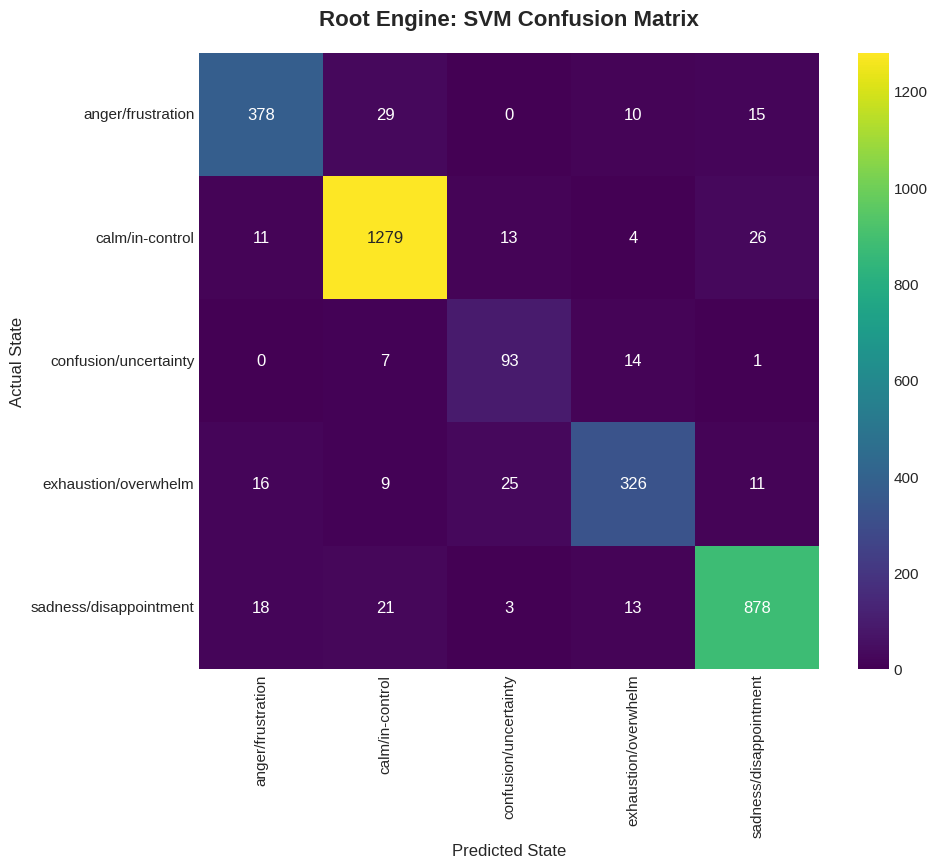

In [ ]:
# Generate the Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=root_svm.classes_)

# Plot
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='viridis',
    xticklabels=root_svm.classes_, 
    yticklabels=root_svm.classes_
)

plt.title('Root Engine: SVM Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Predicted State', fontsize=12)
plt.ylabel('Actual State', fontsize=12)
plt.show()

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; ">

What We’ve Accomplished

Data Refinement: we transformed a generic 6-class dataset into 5 Consolidated Emotional States specifically mapped to the mission of the app. 
Visual Exploration: we didn't accept the first graph; we changed the perspective from 2D to 3D and eventually to Centroid Islands to try to view the different perspectives of the data. We visually proved that low-dimensional visualizations (PCA/t-SNE) are insufficient for this complexity, justifying the need for our advanced model.

The Baseline Engine: we built a Linear SVM with a TF-IDF pipeline that achieved:

92% Overall Accuracy.

94-96% Recall on the critical "Calm" and "Sadness" classes. 

Error Identification: our Confusion Matrix shows exactly where the leaks are: confusion/uncertainty is leaking into exhaustion/overwhelm (14 samples). This gives we a clear target for improvement.
</div>